In [37]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
df = df = pd.read_csv('premier_league_complete_stats_until31thGameDayOnSeason2025-26.csv', encoding='latin-1')
df = df.drop(['team_name', 'bigChancesMissed', 'cleanSheet', 'clearances', 'dispossessed', 'dribbledPast', 'errorLeadToGoal', 'errorLeadToShot',
          'freeKickGoal',  'goalsPrevented', 'headedGoals', 'highClaims', 'hitWoodwork', 'leftFootGoals', 'savesParried',
          'offsides', 'ownGoals', 'passToAssist', 'penaltiesTaken', 'penaltyConceded', 'penaltyConversion', 'setPieceConversion',
          'penaltyFaced', 'penaltyGoals', 'penaltySave', 'penaltyWon', 'possessionWonAttThird', 'punches', 'shotFromSetPiece',
          'redCards', 'rightFootGoals', 'savedShotsFromInsideTheBox', 'savedShotsFromOutsideTheBox', 'saves', 'savesCaught', 
          'shotsFromOutsideTheBox', 'shotsOffTarget', 'shotsOnTarget',], axis=1)

# df.isna().sum()
le = LabelEncoder()
df['position'] = le.fit_transform(df['position'])
df['expectedGoals'] = df['expectedGoals'].fillna(df['expectedGoals'].median())
df['expectedAssists'] = df['expectedAssists'].fillna(df['expectedAssists'].median())

x = df[['accurateCrosses', 'accurateFinalThirdPasses', 'accurateLongBalls',  'accuratePasses', 'aerialDuelsWon', 'assists', 'ballRecovery',
        'bigChancesCreated', 'expectedAssists', 'expectedGoals', 'goals', 'goalsAssistsSum', 'groundDuelsWon', 'keyPasses', 'successfulDribbles',
        'tacklesWon', 'totalCross', 'totalDuelsWon',  'totalPasses', 'totalShots', 
        'yellowCards', 'touches', 'accurateOwnHalfPasses' ]]

scaler =StandardScaler()
x_scaled = scaler.fit_transform(x)
df

,player_name,position,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,...,totalDuelsWonPercentage,totalLongBalls,totalOppositionHalfPasses,totalOwnHalfPasses,totalPasses,totalShots,totwAppearances,touches,wasFouled,yellowCards
0,Declan Rice,3,41,28.082192,459,72,48.648649,891,687,1578,...,61.111111,148,1054,743,1797,36,3,2327,8,2
1,Gabriel Magalhães,0,1,20.000000,180,63,46.323529,512,747,1259,...,70.334928,136,622,797,1419,18,5,1747,27,3
2,Bukayo Saka,1,36,32.432432,300,14,36.842105,419,105,524,...,53.020134,38,557,126,683,63,4,1236,51,1
3,Martín Zubimendi,3,2,18.181818,369,48,49.484536,833,661,1494,...,60.189573,97,985,709,1694,26,2,2026,10,4
4,Max Dowman,3,0,0.000000,9,0,0.000000,13,3,16,...,42.857143,0,14,3,17,5,0,51,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,Tolu Arokodare,1,0,0.000000,50,1,16.666667,102,49,151,...,46.825397,6,169,73,242,39,0,529,13,1
513,Fer López,3,1,25.000000,31,1,25.000000,58,17,75,...,31.250000,4,80,23,103,5,0,156,4,1
514,Matt Doherty,0,2,28.571429,38,12,38.709677,91,125,216,...,50.666667,31,125,143,268,3,0,386,5,4
515,Toti Gomes,0,3,30.000000,52,23,35.384615,175,357,532,...,60.810811,65,236,381,617,4,0,786,8,2


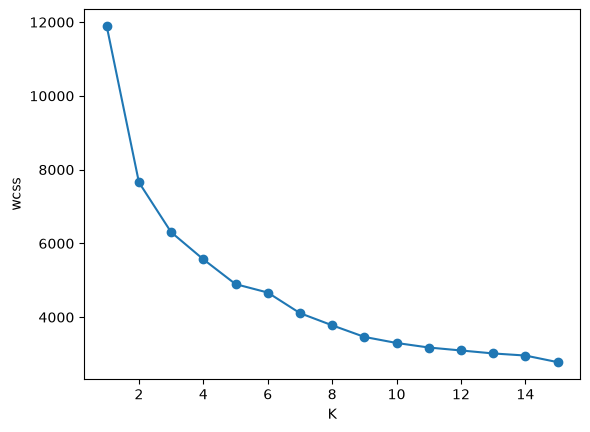

In [38]:
wcss = []
for k in range(1,16):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,16), wcss, marker='o')
plt.xlabel('K')
plt.ylabel('wcss')
plt.show()

In [57]:
pca = PCA()
pca.fit(x_scaled)

# 4. Scree Plot (Cumulative Variance)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_85 = np.argmax(cumulative_variance >= 0.85) + 1

print(cumulative_variance)
print(n_components_85)

[0.51657178 0.69826484 0.79594355 0.8512449  0.88470796 0.90898683
 0.93122526 0.95020896 0.96273386 0.97152112 0.97885379 0.98352245
 0.98725369 0.99059933 0.99375614 0.99605015 0.99784486 0.9994704
 0.99983853 0.99997162 1.         1.         1.        ]
4


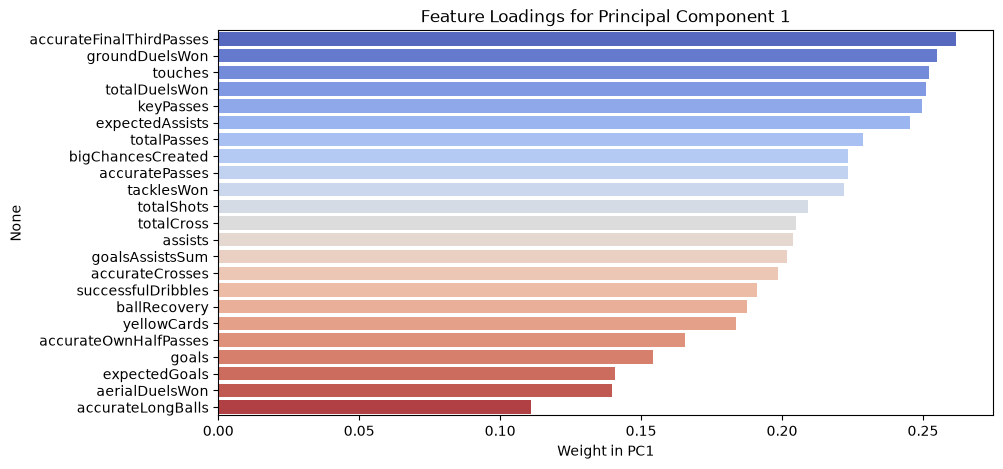

In [73]:
loadings = pd.Series(pca.components_[0], index=x.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=loadings.values, y=loadings.index, palette='coolwarm')
plt.title('Feature Loadings for Principal Component 1')
plt.xlabel('Weight in PC1')
plt.show()

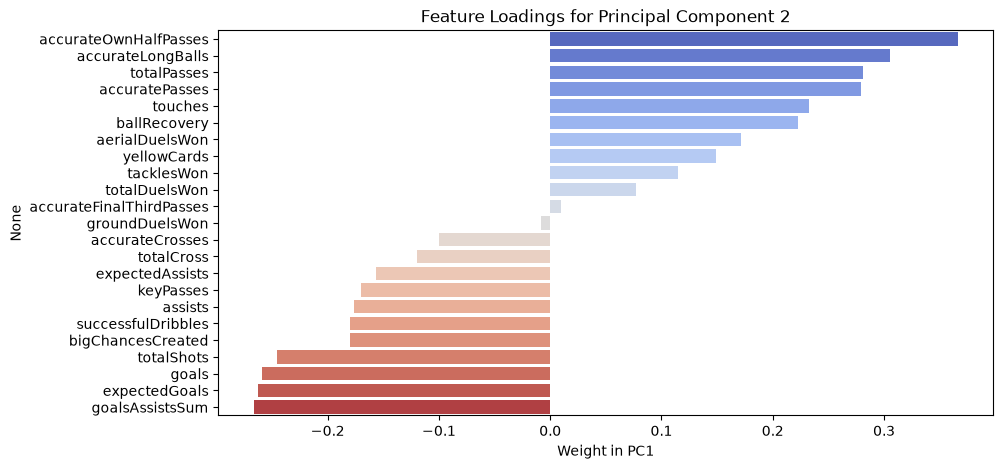

In [74]:
loadings = pd.Series(pca.components_[1], index=x.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=loadings.values, y=loadings.index, palette='coolwarm')
plt.title('Feature Loadings for Principal Component 2')
plt.xlabel('Weight in PC1')
plt.show()

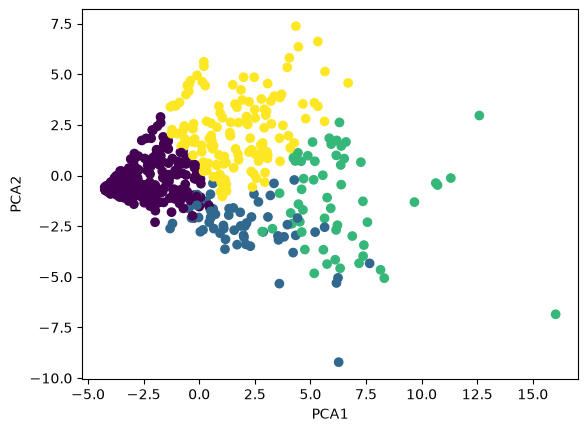

In [75]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
k=4

model = KMeans(n_clusters=k, init='k-means++', random_state=42)
df['Cluster_Raw'] = model.fit_predict(x_scaled)

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

df['PCA1'] = x_pca[: , 0]
df['PCA2'] =x_pca[: , 1]

scatter = plt.scatter(df['PCA1'], df['PCA2'], c=df['Cluster_Raw'], cmap='viridis')
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.show() 

In [76]:
# Գտնում ենք այն տողի ինդեքսը, որտեղ PLT2-ը (կամ PCA2-ը) առավելագույնն է
top_indices = df['PCA2'].nlargest(5).index

# Տպում ենք այդ խաղացողների անունները (ենթադրենք սյունակը player_name է)
print(df.loc[top_indices, 'player_name'])

223          Lewis Dunk
106     Virgil van Dijk
199    Joachim Andersen
133     Trevoh Chalobah
179     Jordan Pickford
Name: player_name, dtype: object


In [77]:
top_indices = df['PCA2'].nsmallest(5).index

# Տպում ենք այդ խաղացողների անունները (ենթադրենք սյունակը player_name է)
print(df.loc[top_indices, 'player_name'])

26      Erling Haaland
50     Bruno Fernandes
112       Hugo Ekitiké
154        Igor Thiago
2          Bukayo Saka
Name: player_name, dtype: object


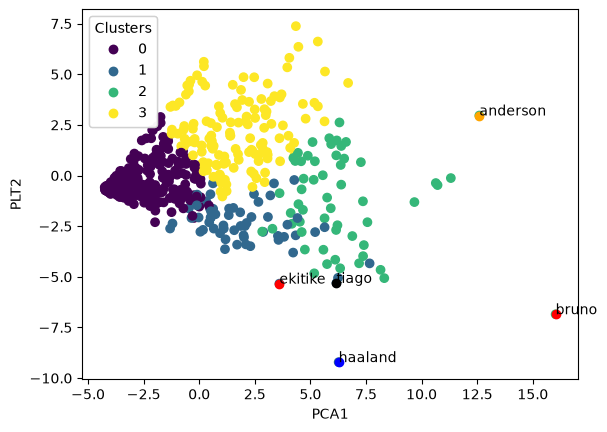

In [78]:
best_md = df[df['player_name']== 'Elliot Anderson']
best_fwd = df[df['player_name']== 'Igor Thiago']
best_goalscorer = df[df['player_name']== 'Erling Haaland']
best_assistent = df[df['player_name']== 'Bruno Fernandes']
best_transfer = df[df['player_name']== 'Hugo Ekitiké']

scatter = plt.scatter(df['PCA1'], df['PCA2'], c=df['Cluster_Raw'], cmap='viridis')
plt.scatter(best_md['PCA1'], best_md['PCA2'], color='orange')
plt.scatter(best_fwd['PCA1'], best_fwd['PCA2'], color='black')
plt.scatter(best_goalscorer['PCA1'], best_goalscorer['PCA2'], color='blue')
plt.scatter(best_assistent['PCA1'], best_assistent['PCA2'], color='red')
plt.scatter(best_transfer['PCA1'], best_transfer['PCA2'], color='red')

plt.text(best_md['PCA1'], best_md['PCA2'], 'anderson')
plt.text(best_fwd['PCA1'], best_fwd['PCA2'], 'tiago')
plt.text(best_goalscorer['PCA1'], best_goalscorer['PCA2'], 'haaland')
plt.text(best_assistent['PCA1'], best_assistent['PCA2'], 'bruno')
plt.text(best_transfer['PCA1'], best_transfer['PCA2'], 'ekitike')

plt.xlabel('PCA1')
plt.ylabel('PLT2')
legend1 = plt.legend(*scatter.legend_elements(), title="Clusters")
plt.gca().add_artist(legend1) 
plt.show()  

In [79]:
df.groupby('Cluster_Raw')[['accurateCrosses', 'accurateFinalThirdPasses', 'accurateLongBalls',  'accuratePasses', 'aerialDuelsWon', 'assists', 'ballRecovery',
        'bigChancesCreated', 'expectedAssists', 'expectedGoals', 'goals', 'goalsAssistsSum', 'groundDuelsWon', 'keyPasses', 'successfulDribbles',
        'tacklesWon', 'totalCross', 'totalDuelsWon',  'totalPasses', 'totalShots']].mean()

,accurateCrosses,accurateFinalThirdPasses,accurateLongBalls,accuratePasses,aerialDuelsWon,assists,ballRecovery,bigChancesCreated,expectedAssists,expectedGoals,goals,goalsAssistsSum,groundDuelsWon,keyPasses,successfulDribbles,tacklesWon,totalCross,totalDuelsWon,totalPasses,totalShots
Cluster_Raw,,,,,,,,,,,,,,,,,,,,
0,1.617424,39.753788,10.064394,161.662879,6.738636,0.359848,23.810606,0.594697,0.357095,0.912931,0.431818,0.791667,16.257576,3.886364,3.636364,4.863636,7.977273,22.996212,200.621212,5.818182
1,5.366667,133.133333,10.916667,327.200000,32.283333,1.800000,55.783333,3.516667,1.709244,6.070393,6.233333,8.033333,58.850000,18.833333,16.400000,11.383333,26.166667,91.133333,429.016667,40.750000
2,20.857143,295.125000,40.357143,857.839286,20.589286,3.589286,109.339286,6.964286,3.714862,3.348804,3.500000,7.089286,98.017857,36.089286,24.892857,26.232143,86.035714,118.607143,1022.928571,35.178571
3,4.948905,141.255474,53.627737,822.919708,38.583942,1.072993,97.328467,1.678832,1.068886,1.234929,0.927007,2.000000,54.832117,10.401460,6.452555,19.759124,20.072993,93.416058,983.233577,12.408759
